In [1]:
import os, glob, time
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


In [2]:
from google.colab import drive
drive.mount('/content/drive')

DRIVE       = "/content/drive/MyDrive"
DATA_ROOT   = f"{DRIVE}/drone-val"                         #validation
OUT         = f"{DRIVE}/outputs_val/dehazenet_v6r"
BASE_CKPT   = f"{DRIVE}/checkpoints/dehazenet_v4r.pth"     #frozen t and A, 6-scene training
CKPT        = f"{DRIVE}/checkpoints/dehazenet_v6r.pth"     #residual branch only
print(OUT, BASE_CKPT, CKPT)

Mounted at /content/drive
/content/drive/MyDrive/outputs_val/dehazenet_v6r /content/drive/MyDrive/checkpoints/dehazenet_v4r.pth /content/drive/MyDrive/checkpoints/dehazenet_v6r.pth


parameter

In [3]:
#training data
TRAIN_STEP = 5            #every 5th frame, ~400 pairs
LONG_SIDE = 512           #resize before caching in RAM
CROP = 256

#training
EPOCHS = 30
BATCH = 16
LR = 1e-3

#physics, same as DCP
A_PATCH = 15              #dark channel patch for A
A_TOP = 0.001             #brightest 0.1% of the dark channel
T_MIN = 0.1

#t refinement at inference (guided filter, as in the paper)
GF_RADIUS = 60
GF_EPS = 1e-3

training data

In [4]:
data = np.load(f"{DRIVE}/train_cache_6scenes_step5_512.npz")
pairs = list(zip(data["hazy"], data["gt"]))
print(len(pairs), "pairs")


class PairDataset(torch.utils.data.Dataset):
    #random crop + horizontal flip
    def __len__(self):
        return len(pairs)

    def __getitem__(self, i):
        hazy, gt = pairs[i]
        y = np.random.randint(0, hazy.shape[0] - CROP + 1)
        x = np.random.randint(0, hazy.shape[1] - CROP + 1)
        hazy, gt = hazy[y:y + CROP, x:x + CROP], gt[y:y + CROP, x:x + CROP]
        if np.random.rand() < 0.5:
            hazy, gt = hazy[:, ::-1], gt[:, ::-1]
        to_t = lambda a: torch.from_numpy(a.copy()).permute(2, 0, 1).float() / 255
        return to_t(hazy), to_t(gt)


loader = torch.utils.data.DataLoader(PairDataset(), batch_size=BATCH, shuffle=True, num_workers=2, drop_last=True)

366 pairs


model

In [5]:
class DehazeNet(nn.Module):
    #t branch + learned A branch (v2 architecture)
    def __init__(self):
        super().__init__()
        self.f1 = nn.Conv2d(3, 16, 5, padding=2)
        self.f2 = nn.ModuleList([nn.Conv2d(4, 16, k, padding=k // 2) for k in (3, 5, 7)])
        self.f4 = nn.Conv2d(48, 1, 6)
        self.a_head = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(32, 3), nn.Sigmoid())

    def transmission(self, x):
        b, _, h, w = x.shape
        x = self.f1(x).view(b, 4, 4, h, w).max(dim=2)[0]
        x = torch.cat([conv(x) for conv in self.f2], dim=1)
        x = F.max_pool2d(x, 7, stride=1, padding=3)
        x = self.f4(F.pad(x, (2, 3, 2, 3)))
        return torch.sigmoid(x)

    def forward(self, x):
        return self.transmission(x), self.a_head(x)


class Residual(nn.Module):
    #multiplicative, bounded correction: J = Jp * (1 + R), R in [-max_gain, max_gain]; zero-init so it starts as v4r
    def __init__(self, c=16, max_gain=0.2):
        super().__init__()
        self.max_gain = max_gain
        self.body = nn.Sequential(
            nn.Conv2d(6, c, 3, padding=1), nn.ReLU(),
            nn.Conv2d(c, c, 3, padding=2, dilation=2), nn.ReLU(),
            nn.Conv2d(c, c, 3, padding=4, dilation=4), nn.ReLU(),
            nn.Conv2d(c, 3, 3, padding=1))
        nn.init.zeros_(self.body[-1].weight)
        nn.init.zeros_(self.body[-1].bias)

    def forward(self, I, Jp):
        return self.max_gain * torch.tanh(self.body(torch.cat([I, Jp], dim=1)))


def recover(I, t, A):
    A = A[:, :, None, None]
    return ((I - A) / t.clamp(min=T_MIN) + A).clamp(0, 1)


net = DehazeNet().to(DEVICE)
net.load_state_dict(torch.load(BASE_CKPT, map_location=DEVICE))
net.eval()
for p in net.parameters():
    p.requires_grad = False

res = Residual().to(DEVICE)
print(f"{sum(p.numel() for p in net.parameters())} frozen | {sum(p.numel() for p in res.parameters())} residual params")

13492 frozen | 5955 residual params


train

In [6]:
opt = torch.optim.Adam(res.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, EPOCHS)

for epoch in range(EPOCHS):
    res.train()
    total = 0
    for hazy, gt in loader:
        hazy, gt = hazy.to(DEVICE), gt.to(DEVICE)
        with torch.no_grad():
            t, A = net(hazy)
            Jp = recover(hazy, t, A)
        J = (Jp * (1 + res(hazy, Jp))).clamp(0, 1)
        loss = F.l1_loss(J, gt)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item()
    sched.step()
    print(f"epoch {epoch + 1}/{EPOCHS} | L1 {total / len(loader):.4f}")

os.makedirs(os.path.dirname(CKPT), exist_ok=True)
torch.save(res.state_dict(), CKPT)

epoch 1/30 | L1 0.0636
epoch 2/30 | L1 0.0637
epoch 3/30 | L1 0.0630
epoch 4/30 | L1 0.0625
epoch 5/30 | L1 0.0635
epoch 6/30 | L1 0.0635
epoch 7/30 | L1 0.0632
epoch 8/30 | L1 0.0633
epoch 9/30 | L1 0.0626
epoch 10/30 | L1 0.0632
epoch 11/30 | L1 0.0625
epoch 12/30 | L1 0.0616
epoch 13/30 | L1 0.0627
epoch 14/30 | L1 0.0623
epoch 15/30 | L1 0.0622
epoch 16/30 | L1 0.0613
epoch 17/30 | L1 0.0615
epoch 18/30 | L1 0.0620
epoch 19/30 | L1 0.0618
epoch 20/30 | L1 0.0618
epoch 21/30 | L1 0.0622
epoch 22/30 | L1 0.0615
epoch 23/30 | L1 0.0613
epoch 24/30 | L1 0.0615
epoch 25/30 | L1 0.0612
epoch 26/30 | L1 0.0615
epoch 27/30 | L1 0.0613
epoch 28/30 | L1 0.0616
epoch 29/30 | L1 0.0616
epoch 30/30 | L1 0.0610


inference

In [7]:
def guided_filter(guide, src, r=GF_RADIUS, eps=GF_EPS):
    box = lambda x: cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1))
    mean_I, mean_p = box(guide), box(src)
    a = (box(guide * src) - mean_I * mean_p) / (box(guide * guide) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * guide + box(b)


@torch.no_grad()
def dehaze_full(rgb):
    #v4r physics output (t at long side LONG_SIDE) + residual at full resolution
    net.eval(); res.eval()
    I = torch.from_numpy(rgb.copy()).permute(2, 0, 1)[None].float().div(255).to(DEVICE)
    H, W = I.shape[2:]
    t_small, A = net(F.interpolate(I, scale_factor=LONG_SIDE / max(H, W), mode='bilinear'))
    t = F.interpolate(t_small, size=(H, W), mode='bilinear')[0, 0].cpu().numpy()
    t = guided_filter(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32) / 255, t)
    Jp = recover(I, torch.from_numpy(t).to(DEVICE)[None, None], A)
    J = (Jp * (1 + res(I, Jp))).clamp(0, 1)
    return (J[0].permute(1, 2, 0).cpu().numpy() * 255 + 0.5).astype(np.uint8), t


def dehaze(hazy):
    return dehaze_full(np.asarray(hazy))[0]

preview a single image

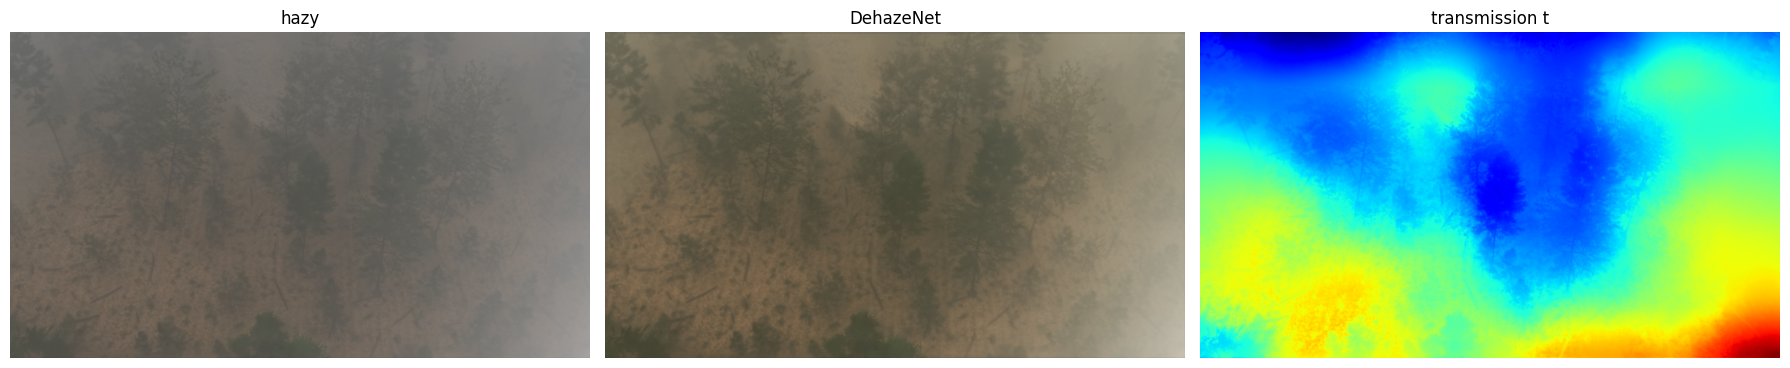

In [8]:
hazy_paths = sorted(glob.glob(f"{DATA_ROOT}/hazy/*"))
os.makedirs(OUT, exist_ok=True)

hazy = np.asarray(Image.open(hazy_paths[0]).convert('RGB'))
J, t = dehaze_full(hazy)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, im, title, cmap in zip(ax, [hazy, J, t], ['hazy', 'DehazeNet', 'transmission t'], [None, None, 'jet']):
    a.imshow(im, cmap=cmap); a.set_title(title); a.axis('off')
plt.tight_layout(); plt.show()

run over the test set

In [9]:
for p in hazy_paths:
    hazy = Image.open(p).convert('RGB')
    t0 = time.time()
    pred = dehaze(hazy)
    dt = time.time() - t0
    Image.fromarray(pred).save(f"{OUT}/{os.path.basename(p)}")
    print(f"{os.path.basename(p)} | {hazy.size[0]}x{hazy.size[1]} | {dt:.2f}s")

08_overcast_hover-southwest_0001.png | 1280x720 | 0.07s
08_overcast_hover-southwest_0015.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0030.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0045.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0060.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0075.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0090.png | 1280x720 | 0.10s
08_overcast_hover-southwest_0105.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0120.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0135.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0150.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0165.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0180.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0195.png | 1280x720 | 0.09s
08_overcast_hover-southwest_0210.png | 1280x720 | 0.09s


evaluate

In [10]:
!pip install -q pyiqa
!rm -rf /content/vx
!git clone -q --depth 1 https://github.com/fahimrayhan/vidhance-extendview.git /content/vx

import sys
from pathlib import Path
sys.path.insert(0, "/content/vx/dehazing")
from evaluation import evaluate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 238MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/LPIPS_v0.1_alex-df73285e.pth" to /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth



100%|██████████| 5.87k/5.87k [00:00<00:00, 23.0kB/s]


Loading pretrained model LPIPS from /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth
Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/niqe_modelparameters.mat" to /root/.cache/torch/hub/pyiqa/niqe_modelparameters.mat



100%|██████████| 8.15k/8.15k [00:00<00:00, 16.5MB/s]


Downloading: "https://huggingface.co/chaofengc/IQA-PyTorch-Weights/resolve/main/brisque_svm_weights.pth" to /root/.cache/torch/hub/pyiqa/brisque_svm_weights.pth



100%|██████████| 112k/112k [00:00<00:00, 612kB/s]


In [11]:
import pandas as pd
OUTPUTS = Path(f"{DRIVE}/outputs_val")
NEW = ["dehazenet_v6r"]
ALL = OUTPUTS / "per_image_val.csv"

per_image_new, _ = evaluate(DATA_ROOT, {m: str(OUTPUTS / m) for m in NEW})
old = pd.read_csv(ALL) if ALL.exists() else per_image_new.iloc[0:0]
keep_hazy = per_image_new if not (old.method == "hazy").any() else per_image_new[per_image_new.method != "hazy"]
per_image = pd.concat([old[~old.method.isin(NEW)], keep_hazy])
per_image.to_csv(ALL, index=False)

summary = per_image.groupby("method", sort=False).mean(numeric_only=True)
summary.to_csv(OUTPUTS / "summary_val.csv")
summary

[1/15] 08_overcast_hover-southwest_0001.png
[2/15] 08_overcast_hover-southwest_0015.png
[3/15] 08_overcast_hover-southwest_0030.png
[4/15] 08_overcast_hover-southwest_0045.png
[5/15] 08_overcast_hover-southwest_0060.png
[6/15] 08_overcast_hover-southwest_0075.png
[7/15] 08_overcast_hover-southwest_0090.png
[8/15] 08_overcast_hover-southwest_0105.png
[9/15] 08_overcast_hover-southwest_0120.png
[10/15] 08_overcast_hover-southwest_0135.png
[11/15] 08_overcast_hover-southwest_0150.png
[12/15] 08_overcast_hover-southwest_0165.png
[13/15] 08_overcast_hover-southwest_0180.png
[14/15] 08_overcast_hover-southwest_0195.png
[15/15] 08_overcast_hover-southwest_0210.png


,psnr,ssim,ciede2000,lpips,niqe,brisque,e,r,sigma
method,,,,,,,,,
hazy,16.628117,0.484373,14.095817,0.662183,5.232528,29.706108,0.000000,1.000000,0.0
dehazenet_v4r,18.670550,0.514562,10.504603,0.620219,5.034739,27.849915,1.600775,1.125655,0.0
cap,19.711093,0.551034,12.100555,0.585522,4.714936,25.689669,11.603946,1.414628,0.0
dehazenet_v6r,17.159221,0.520716,11.233822,0.588252,5.045262,29.388139,4.525737,1.376291,0.0
